# DexJoCo［灵巧手操作基准］：AMD［超威半导体］原生数组计算训练与评估

本流程从浇花任务的真实数据开始，在原生 AMD［超威半导体］设备的 JAX［高性能数组计算框架］中执行 Pi0.5［机器人策略模型］低秩适配训练，再启动本次检查点的策略服务，并用官方灵巧手客户端闭环评估。默认完成一个任务；双臂任务必须匹配 44 维检查点与对应数据，不能复用单臂权重。

流程：固定源码与依赖 → 后端预检 → 数据审计与统计 → 真实训练 → 本次权重身份核对 → 官方闭环评估 → 视频和逐回合结果。历史比赛成绩不参与本次结果计算。

## 阅读与完整复现

本笔记本保存真实设备结果，下载后不运行也能查看训练曲线、同种子逐回合对照和代表性视频。默认模式只读取随课程分发的证据快照，不需要设备。

完整复现时设置环境变量 `AMD_RUN_FULL=1`，修改下方路径和新的运行目录，再从头执行全部单元。正式步数、全数据范围及 20 个种子已经写入配置。下载和安装单独显式启用；已准备好的设备不重复下载。

证据快照是此前实际任务的只读记录。下方完整复现代码的关闭状态不会被称作本次重新训练通过；历史整本执行验收另行标注。

## 官方计算配置与本次实验的对应关系

[官方论文第二版](https://arxiv.org/html/2605.16257v2)报告训练使用 NVIDIA［英伟达］A6000 和 L40 显卡，部署使用 NVIDIA［英伟达］RTX 4090 显卡；没有明确给出单任务训练小时数或各模型使用的显卡数量。[官方模型卡](https://huggingface.co/DexJoCo/DexJoCo-Pi05)给出单臂 30000 步、双臂及多任务 60000 步；[官方训练配置](https://github.com/brave-eai/dexjoco/blob/main/openpi/config.yaml)默认批量 32，并把批量 1 注释为测试用途。

| 比较项 | 官方单臂配方 | 本次灵巧手设备实验 |
| --- | --- | --- |
| 更新步数 | 30000 | 30000 |
| 每步批量 | 32 | 1，梯度累积 1，有效批量 1 |
| 样本呈现次数 | 960000 | 30000，允许重复采样 |
| 起始权重 | 通用 `pi05_base/params` | 官方已经适配浇花任务的 `pi05_dexjoco_ckpt/water_plant` |
| 评估规模 | 每任务每设置 3 个种子，每种子 50 回合 | 起始任务权重及本次继续训练权重，各 20 回合，种子 100–119 |

**本次是从官方任务权重继续适配的完整设备工作流，不能称作从通用基座按论文配方重新训练。** 下方对照中的“基座”指本次起始任务权重，不是从未见过该任务的通用模型。两组各 20 回合使用官方任务时长，但回合数量与论文不同。

本次 30000 次更新已经完成，训练阶段实测 65452.774 秒，即约 18 小时 11 分钟；这是本机小批量配方的实测耗时，不是官方耗时。原生检查点从零编号，最终目录编号为 29999，对应第 30000 次更新。两天内完成单任务适配与课程整理是可行的；论文还覆盖 11 个任务、多种策略、随机化与消融实验，不能以单任务耗时代表整篇论文计算需求。


## 严格加载修正后的完整结果

| 实验 | 起始权重 | 本次训练后权重 | 正式评估 |
| --- | --- | --- | --- |
| 厨房，3000 次更新 | 14/20（70%） | 14/20（70%） | 相同种子 100–119，完整 750 步上限 |
| 灵巧手，30000 次更新 | 5/20（25%） | 3/20（15%） | 严格加载、计时前预热，官方异步动作时序，完整任务终止条件 |

**官方异步条件下，本轮继续训练未显示效果提升。** 灵巧手点估计下降 10 个百分点；同种子改善 [111, 116]、退步 [101, 102, 105, 113]。每组只有 20 回合，不能据此断言稳定退化或代表论文完整成绩。训练曲线不能代替闭环成功率。

已定位并修复此前官方权重 0/20 的加载缺陷：辅助代码错误地关闭 LoRA［低秩适配］分支，上游加载器又静默丢弃结构之外的参数。文件内容指纹一致不等于模型完整加载。当前根据检查点元数据选择结构，禁止丢弃额外参数；两组的实际加载审计均确认 20 个任务适配张量，两个模型分支都保留适配器。原 0/20 基线无效，旧对照只作排错历史，不能代表完整官方权重的性能。

当前两组分别预热 19.36 秒、18.45 秒，均恢复随机数状态。两套均完成全数据准备、连续有限的完整目标更新步数和相同种子的两组完整评估；本次重评估复用同一份 30000 步权重，没有重复训练。

### 归一化、动作接口与推理时延

官方与本次统计均为状态 23 维、动作 22 维，分位数最大绝对差约 0.00318，暂未发现明显维度或尺度错误。源码级动作检查确认 22 维策略动作转换到 23 维模拟器动作时，三维位置、16 个手关节保持不变，旋转矩阵往返误差约 3.33×10⁻¹⁶；这只是接口数学检查，不冒充模型推理或任务成功率。

正确加载并预热后的独立种子 100 诊断中，推理中位耗时约 0.897 秒，首次调用约 0.912 秒，已经没有长时间的首次编译。但完整 1000 个仿真步中，仅 552 步执行策略动作，448 步保持姿态；30 步动作块到达时通常只剩 9–13 步可用。诊断单独保存，不计入 20 个正式种子的分母。这说明稳态等待仍显著改变实际动作执行，不能把剩余失败全归因于训练或模型质量。

独立的等待时钟对照已完成：起始权重 12/20（60%），训练后权重 14/20（70%），相同种子 100–119。训练后点估计增加 10 个百分点，但每组只有 20 回合，不能据此宣称稳定提升或严格复现论文成绩。只在等待新动作、缓冲区为空时暂停仿真时钟，保留官方动作合并、观测时间戳、真实环境步进和成功条件。训练与权重均未改变，没有再次训练。它与官方异步评估属于不同部署条件，不能替换官方异步的 5/20 对 3/20。该模式让模拟器等待设备计算，并未缩短实际推理耗时；视频按物理仿真步播放，不展示等待的墙钟时间，逐回合等待休眠累计与完整墙钟时间另存于 `clock_audit.json`，等待休眠累计不含循环处理开销。真实机器人能否保持同等行为仍需另行验证。

### 旧日志与成功视频

旧单任务目录中的浇花种子 0–3 均有成功标记；下方单列旧种子 0 的完整成功视频。另有官方多任务权重的 11 项推理演示，固定种子 0 每项一回合，共 5/11 成功；后续搜索种子得到浇花种子 2 成功。搜索后的成功片段不等于固定种子成功率，运行多任务权重也不代表自己做过多任务联合训练。所有历史视频都与本轮正式分母分开。

自动更新服务此前因内存耗尽退出。本次管理员操作已暂停两个自动更新定时器，当前服务不运行；如需恢复触发器，执行 `sudo systemctl start apt-daily.timer apt-daily-upgrade.timer`。教程不会自动执行系统维护操作。记录在 `results/system/system-maintenance-20261025.json`。


In [1]:
from pathlib import Path
import json
import os
import sys

TOPIC = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'code/amd_benchmarks').is_dir()), None)
if TOPIC is None:
    raise FileNotFoundError('Start Jupyter from the AMD topic directory or notebooks/.')
sys.path.insert(0, str(TOPIC / 'code'))
from amd_benchmarks.notebook_api import run_stage, download_assets, inspect_run, plot_metrics, show_videos
WORK_ROOT = Path(os.environ.get('AMD_WORK_ROOT', str(Path.home() / 'amd-course')))
SRC_ROOT = Path(os.environ.get('SRC_ROOT', str(WORK_ROOT / 'src')))
DATA_ROOT = Path(os.environ.get('DATA_ROOT', str(WORK_ROOT / 'datasets')))
MODEL_ROOT = Path(os.environ.get('MODEL_ROOT', str(WORK_ROOT / 'models')))
ENV_ROOT = Path(os.environ.get('ENV_ROOT', str(WORK_ROOT / 'envs')))
RUN_ROOT = Path(os.environ.get('RUN_ROOT', str(WORK_ROOT / 'runs')))

from amd_benchmarks.evidence import training_summary, plot_training, compare_policies, show_recorded_videos, show_execution_validation, record_live_run
RUN_FULL = os.environ.get('AMD_RUN_FULL', '0') == '1'
RECORDED = TOPIC / 'notebooks/results' / 'dexjoco'
print('完整训练和评估启用：', RUN_FULL)


完整训练和评估启用： False


## 已记录的正式结果

结果读取随笔记本附带的原始指标、权重身份、配置和逐回合文件，并校验内容指纹。记录中的数据范围是训练采样来源，不等于每个样本都被训练遍历。

记录项,实测或配置
任务,water_plant
数据回合／帧数,100 / 27745
真实已记录更新／目标,30000 / 30000
实际批量／梯度累积／有效批量,1 / 1 / 1
学习率或峰值学习率,1e-05
可训练参数,466957072
最后记录损失,0.00023379144840873778
正式训练状态,完成
原始证据目录,/home/aup/amd-notebook-work/runs/dexjoco-formal-20261023-v1
实测训练阶段耗时／小时,18.181


样本更新次数／数据帧数： 1.0813
该比值用于理解数据使用规模；随机有放回采样不保证每个样本都已遍历。
本次权重内容指纹： 7cc8487f7609b05a255c6a942ff4f0f468302bf2bd6a08fafd3d4c7870115761
参数更新前后指纹是否不同： True


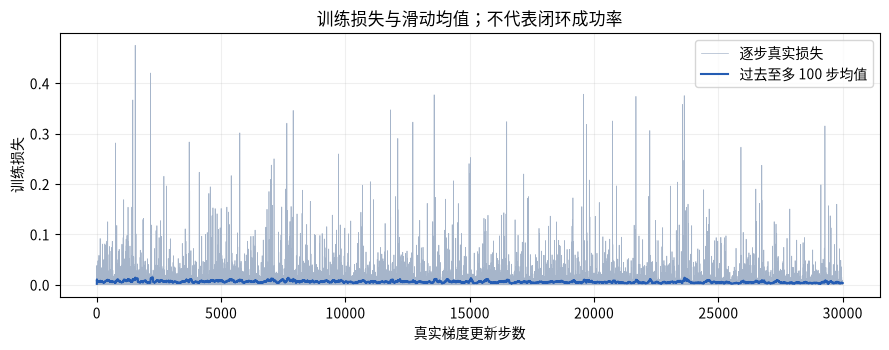

In [2]:
recorded_summary = training_summary(RECORDED)
plot_training(RECORDED)


In [3]:
compare_policies(RECORDED)


策略,成功回合／完整分母,成功率,权重指纹前缀
官方起始任务权重,5 / 20,25.0%,21640047e97354a6
本次训练后权重,3 / 20,15.0%,7cc8487f7609b05a


策略,适配张量数,允许静默丢弃参数,计时前预热／随机数恢复
官方起始任务权重,20,False,True / True
本次训练后权重,20,False,True / True


种子,基座,训练后,同种子变化
100,失败,失败,相同
101,成功,失败,退步
102,成功,失败,退步
103,失败,失败,相同
104,成功,成功,相同
105,成功,失败,退步
106,失败,失败,相同
107,失败,失败,相同
108,失败,失败,相同
109,失败,失败,相同


总体成功率差： -10.0 个百分点
本结果只适用于记录的单任务、种子、划分及配方；相同成功率不代表每个回合行为相同。


In [4]:
show_recorded_videos(RECORDED)


**官方起始任务权重 · 种子 101 · 成功**

**官方起始任务权重 · 种子 100 · 失败**

**本次训练后权重 · 种子 104 · 成功**

**本次训练后权重 · 种子 100 · 失败**

**旧日志中的官方任务权重演示：种子 0 成功；不计入本轮 100–119 的正式分母**

### 整本执行证明与正式实验的区别

全新内核、全部工作负载开启的 20 步整本执行已通过。正式训练另用全数据、30000 步及两组各 20 回合，尚在进行时不填写最终成功率。

In [5]:
show_execution_validation(RECORDED)


**独立的整本执行验收：20 步训练、1 回合评估。下方仅证明执行链路，不计入正式 30000 步实验。**

训练步数,评估分母,成功回合,用途
20,1,0,整本执行验收


## 完整运行：固定源码、数据、训练、对照与评估

以下单元按依赖顺序执行完整任务。训练和评估会等待真实进程完成，失败保留日志并使单元报错。正式训练不能用少量步骤的结果代替。

## 1. 路径与运行配置

把源码、数据、模型与运行目录放在持久化磁盘。复用已有解释器，不把数组计算与模拟器的依赖混装。当前默认训练和评估开关关闭；后续单元启用后会执行真实负载。

In [6]:
CONFIG = {
    'benchmark': 'dexjoco',
    'task': 'water_plant',
    'source_root': str(SRC_ROOT / "dexjoco"),
    'dataset_root': str(DATA_ROOT / "dexjoco/water_plant"),
    'base_model': str(MODEL_ROOT / "dexjoco/pi05_dexjoco_ckpt/water_plant"),
    'run_root': str(RUN_ROOT / "dexjoco-water-plant-v1"),
    'lerobot_source': str(SRC_ROOT / "lerobot/src"),
    'simulator_eval': str(ENV_ROOT / "dexjoco-amd/bin/dexjoco-openpi-eval"),
    'asset_cache': str(WORK_ROOT / 'cache/openpi'),
    'training_recipe': 'upstream_lora',
    'minimum_free_gib': 24,
    'normalization_frames': None,
    'normalization_batch_size': 5,
    'normalization_workers': 2,
    'warmup_steps': 100,
    'eval_seeds': list(range(100, 120)),
    'port': 8122,
    'batch_size': 1,
    'learning_rate': 1e-05,
    'seed': 42,
    'steps': 30000,
    'save_every': 1000,
    'resume': False,
}
# An explicit profile can point at existing source, data and environments.
PROFILE = os.environ.get('AMD_DEXJOCO_CONFIG')
if PROFILE:
    CONFIG = json.loads(Path(PROFILE).read_text(encoding='utf-8'))
TRAIN_PYTHON = Path(os.environ.get('TRAIN_PYTHON', str(ENV_ROOT / 'openpi-amd-jax010/bin/python')))
print(json.dumps(CONFIG, ensure_ascii=False, indent=2))
print('Interpreter:', TRAIN_PYTHON)

# This example profile points at the verified AMD device. Edit all paths on another machine.
USE_VERIFIED_DEVICE_PROFILE = os.environ.get('AMD_USE_DEVICE_PROFILE', '0') == '1'
if USE_VERIFIED_DEVICE_PROFILE and not PROFILE:
    CONFIG = json.loads((TOPIC / 'reproducibility/dexjoco-device-profile.json').read_text(encoding='utf-8'))
CONFIG['run_root'] = os.environ.get('AMD_NEW_RUN_ROOT', CONFIG['run_root'])

CONFIG["warmup_policy"] = True

CONFIG["policy_loader_contract"] = "strict-adapters-v2"

print('实际运行配置：', json.dumps(CONFIG, ensure_ascii=False, indent=2))


{
  "benchmark": "dexjoco",
  "task": "water_plant",
  "source_root": "/home/ubuntu/amd-course/src/dexjoco",
  "dataset_root": "/home/ubuntu/amd-course/datasets/dexjoco/water_plant",
  "base_model": "/home/ubuntu/amd-course/models/dexjoco/pi05_dexjoco_ckpt/water_plant",
  "run_root": "/home/ubuntu/amd-course/runs/dexjoco-water-plant-v1",
  "lerobot_source": "/home/ubuntu/amd-course/src/lerobot/src",
  "simulator_eval": "/home/ubuntu/amd-course/envs/dexjoco-amd/bin/dexjoco-openpi-eval",
  "asset_cache": "/home/ubuntu/amd-course/cache/openpi",
  "training_recipe": "upstream_lora",
  "minimum_free_gib": 24,
  "normalization_frames": null,
  "normalization_batch_size": 5,
  "normalization_workers": 2,
  "warmup_steps": 100,
  "eval_seeds": [
    100,
    101,
    102,
    103,
    104,
    105,
    106,
    107,
    108,
    109,
    110,
    111,
    112,
    113,
    114,
    115,
    116,
    117,
    118,
    119
  ],
  "port": 8122,
  "batch_size": 1,
  "learning_rate": 1e-05,
  "seed

### 环境、版本与资源准备



厨房路径需要官方 `robocasa`、`robosuite` 和 RoboCasa365 配套的 `Isaac-GR00T`。训练器读取 `panda_omron` 数据配置，使用官方机器人元数据切分 16 维状态和 12 维动作。训练数据必须是相应任务的真实三相机数据。

灵巧手路径需要包含 `openpi/`、`configs/rand_obj/` 和模拟器客户端的 DexJoCo 工程。低秩适配配置来自该工程的 `openpi.training.config`，不得用其他机器人配置替代。`lerobot_source` 可以显式指向支持第三版数据格式的机器人学习框架源码；已有环境中的旧版框架不能读取此数据格式。

依赖安装复用各项目解释器。先运行预检，禁止用处理器回退通过设备验收。资源下载单元要求 `DOWNLOAD_ENTRY` 指向已配置的下载入口；源码、模型及数据来源分别见第 11、12 章。大文件放在持久化磁盘，不放在课程仓库。

## 固定版本与设备配置

`reproducibility/source-manifest.json` 记录源码提交及关键文件内容指纹；两个环境清单记录实机安装版本。这些清单用于比对，不是可直接整表安装的依赖锁；厨房环境含系统继承包，设备专用轮包也需要对应官方索引。新建环境须先按第 10–12 章安装设备计算栈，再按清单核对核心库，禁止直接安装上游默认的另一设备计算依赖。

| 组件 | 固定版本 |
| --- | --- |
| 厨房策略源码 | `9d7d7a9eb7ad30bd8ce30448d9ab53a918b45b10` |
| 厨房仿真源码 | `b4684e6ee37d377cc392e98302a6b916d588b415` |
| 机器人仿真组件 | `5ce6643f3092639d08f7b0f90ed1c6a84f50552c` |
| 灵巧手兼容分支源码 | `46fcd70db460b3be5487387adab2aaf3e2e7b74f` |
| 第三版数据读取源码 | `00b5f65752e1e5882f96c99a34e1d8b6d5d67f11` |

灵巧手参考提交包含新版检查点兼容修改，来自公开兼容分支，不能仅克隆官方主线后假设源码相同：

```bash
git clone https://github.com/Ethan-Chen-plus/dexjoco.git "$SRC_ROOT/dexjoco"
git -C "$SRC_ROOT/dexjoco" checkout 46fcd70db460b3be5487387adab2aaf3e2e7b74f
```

厨房核心版本为设备张量库 `2.12.1+rocm7.2`、视觉库 `0.27.1+rocm7.2`、模型库 `4.51.3`、扩散库 `0.30.2`。灵巧手采用数组库 `0.10.0`、设备插件 `0.10.0+rocm7.14.0`、神经网络库 `0.12.8`、检查点库 `0.12.1`，配套处理器版张量库 `2.9.0+cpu` 和视觉库 `0.24.0+cpu`。

灵巧手已有数组计算环境补齐数据加载依赖时，可通过专用下载入口安装：

```bash
"$DOWNLOAD_ENTRY" "$TRAIN_PYTHON" -m pip install \
  'torch==2.9.0+cpu' 'torchvision==0.24.0+cpu' \
  --index-url https://download.pytorch.org/whl/cpu
"$DOWNLOAD_ENTRY" "$TRAIN_PYTHON" -m pip install \
  'datasets==4.0.0' 'pandas==2.3.3' 'pyarrow==21.0.0' \
  'av==15.1.0' 'fsspec==2025.3.0' 'dill==0.3.8' \
  'multiprocess==0.70.16' 'accelerate==1.10.1' \
  'wandb==0.19.11' 'protobuf==6.33.6'
```

课程辅助模块在子进程内适配神经网络库的参数遍历、数组库的自动分片模式，并关闭不适配该设备共享内存上限的编译优先融合阶段；不覆盖上游源码。厨房辅助模块使用数学注意力内核，并在模型库内适配注意力映射。更换核心版本须重新检查反向梯度是否有限。

两个 `*-device-profile.json` 配置指向已有设备路径，采用新的正式实验目录；它们是待运行配置，不代表已完成正式训练。启动厨房笔记本时设置：

```bash
export AMD_ROBOCASA_CONFIG="$PWD/reproducibility/robocasa-device-profile.json"
export TRAIN_PYTHON=/home/aup/envs/robocasa365-rocm-py312/bin/python
```

灵巧手改用 `AMD_DEXJOCO_CONFIG` 和对应解释器。启动目录应为本专题根目录；两本笔记本也支持从其 `notebooks/` 目录打开。交互内核与设备训练进程分开。`TRAIN_PYTHON` 选择训练解释器，交互内核可以复用厨房环境。给已有交互解释器安装固定组件：

```bash
"$DOWNLOAD_ENTRY" "$NOTEBOOK_PYTHON" -m pip install \
  'ipykernel==6.29.5' 'ipython==8.37.0' \
  'nbclient==0.10.2' 'nbformat==5.10.4' \
  'matplotlib==3.10.3' 'contourpy==1.3.2' 'kiwisolver==1.4.9'
```

旧系统图表轮包可能按旧数组库编译；不能仅检查模块是否存在，必须实际生成图表。

灵巧手还需预取语言分词资源。笔记本下载单元包含对应的公开云存储命令；`asset_cache` 指定其持久缓存目录，已有设备配置复用现存缓存。模型与数据阶段拒绝临时发起资源下载，缺缓存会明确报错。

灵巧手训练默认要求至少 24 GiB 可用系统内存。这是启动门槛，不是实测峰值或不会耗尽内存的保证；统一内存同时承载主机加载、设备参数、编译与优化器。按运行时峰值调整门槛，并保留系统余量。磁盘空闲检查同样只检查启动门槛。灵巧手正式实验默认要求 24 GiB 空闲磁盘，为原生检查点和原子保存时的新旧副本留空间；一份短程原生检查点约为 8.7 GiB。

可以使用配套的整本执行器验证单元顺序：

```bash
export TRAIN_PYTHON=/home/aup/envs/openpi-amd-jax010/bin/python
export JUPYTER_PATH=/home/aup/amd-notebook-work/jupyter/share/jupyter
/home/aup/envs/robocasa365-rocm-py312/bin/python code/execute_course_notebook.py \
  notebooks/18_dexjoco_amd_train_eval.ipynb \
  --profile reproducibility/dexjoco-device-profile.json \
  --kernel amd-course --enable-workloads --output /path/to/new/executed_18.ipynb
```

使用前把配置中的运行目录改为新目录，需要检查环境时，可在独立目录将目标总步数改为 2–20、评估选 1 个种子；该结果只用于执行验收。正式配置使用全部数据与完整步数，不能将短程结果作为正式实验。其他机器用自己的交互解释器及内核名称；输出路径必须是新文件。执行器默认不限制单元时长，支持长训练；可用 `--timeout` 显式设置秒数。执行失败仍保存当时输出并返回异常。此执行器不会自动启用资源下载。



## 2. 源码、依赖与资产

按配套说明中的固定版本准备源码及环境。下载单元真实执行资源下载命令；已有完整资产时保持关闭。`DOWNLOAD_ENTRY` 指向已配置的专用下载入口。模型权限需事先授权；不把访问令牌写进笔记本。

In [7]:
TOKENIZER_CACHE = Path(CONFIG.get('asset_cache', str(Path.home() / '.cache/openpi')))
DOWNLOADS = [
    ['curl', '--fail', '--location', '--retry', '3', '--create-dirs', '--output', str(TOKENIZER_CACHE / 'big_vision/paligemma_tokenizer.model'), 'https://storage.googleapis.com/big_vision/paligemma_tokenizer.model'],
    ['hf', 'download', 'DexJoCo/DexJoCo-Datasets-LeRobot', '--repo-type', 'dataset', '--include', 'water_plant/**', '--local-dir', str(Path(CONFIG['dataset_root']).parent)],
    ['hf', 'download', 'DexJoCo/DexJoCo-Pi05', '--include', 'pi05_dexjoco_ckpt/water_plant/**', '--local-dir', str(Path(CONFIG['base_model']).parents[1])],
]
RUN_DOWNLOAD = False
download_assets(CONFIG, DOWNLOADS, enabled=RUN_DOWNLOAD)


Resource downloads disabled; reuse existing local assets or enable this stage explicitly.


## 3. AMD［超威半导体］后端预检

设备检查会做真实矩阵乘法，并拒绝处理器回退。检查通过只代表运行后端可用，不代表机器人任务成功。

In [8]:
RUN_PREFLIGHT = RUN_FULL
preflight_result = run_stage(CONFIG, 'preflight', TRAIN_PYTHON, enabled=RUN_PREFLIGHT)


preflight: disabled. No workload was executed and no result is claimed.


## 4. 数据准备与输入契约

检查真实回合数据并重新计算状态、动作归一化统计。正式训练使用全数据统计；只有链路检查时可以显式设置 normalization_frames 为有限帧数，且必须记录该限制。单臂输出 22 维旋转向量动作，模型内部填充维度由官方配置决定。

In [9]:
RUN_PREPARE = RUN_FULL
prepare_result = run_stage(CONFIG, 'prepare', TRAIN_PYTHON, enabled=RUN_PREPARE)


prepare: disabled. No workload was executed and no result is claimed.


## 5. 启动前确认训练计划

下表显示实际批量、梯度累积和步数。学习率与冻结范围写入运行记录；可训练参数量及显存峰值以运行时实测为准。本节正式运行使用配置中的完整目标步数；少量步数验收必须使用其他独立目录，不能混入正式对照。

In [10]:
plan = {k: CONFIG[k] for k in ['task', 'steps', 'batch_size', 'learning_rate', 'training_recipe']}
plan.update(gradient_accumulation=1, effective_batch=CONFIG['batch_size'], memory_basis=('RoboCasa: batch 1 device allocation peak 10.73 GiB measured in a 3-step validation; host RAM is additional.' if CONFIG['benchmark'] == 'robocasa' else 'DexJoCo: 32-48 GiB unified working-memory estimate from 7.2 GiB weights, host/device copies and compilation/activations; full-training peak unverified.'), freeze_scope=('action_head.vlln + action_head.vl_self_attention only' if CONFIG['benchmark'] == 'robocasa' else 'upstream model freeze filter; LoRA and all other parameters outside that filter are trainable'))
print(json.dumps(plan, ensure_ascii=False, indent=2))


{
  "task": "water_plant",
  "steps": 30000,
  "batch_size": 1,
  "learning_rate": 1e-05,
  "training_recipe": "upstream_lora",
  "gradient_accumulation": 1,
  "effective_batch": 1,
  "memory_basis": "DexJoCo: 32-48 GiB unified working-memory estimate from 7.2 GiB weights, host/device copies and compilation/activations; full-training peak unverified.",
  "freeze_scope": "upstream model freeze filter; LoRA and all other parameters outside that filter are trainable"
}


## 6. 执行真实训练

启用后等待真实训练进程结束。异常会保留日志并使单元失败，不读取历史权重补齐结果。已有检查点时必须显式恢复或更换目录。

## 直接展开训练实现

本节把正式运行使用的数据准备、训练和评估实现展开为代码单元。训练入口直接调用下方函数，能够逐步查看冻结范围、损失、梯度、参数更新、保存与加载；配置、训练曲线和历史评估输出沿用本篇对应的真实记录。

### 正式配方与训练、保存和评估

下面是实际源码展开后的代码单元，包含数据、模型、损失、梯度更新和保存逻辑；完整运行开关打开时在当前笔记本内执行。来源：`code/amd_benchmarks/dexjoco.py`；SHA256［256位安全散列］：`2952599b532442a422325fe63fb67e78f6a541858e3039fe8ab4320d7af1cb87`。

In [11]:
if RUN_FULL:
    """DexJoCo native ROCm JAX LoRA training and official simulator evaluation."""

    import dataclasses

    import importlib.util

    import json

    import os

    from pathlib import Path

    import re

    import socket

    import subprocess

    import sys

    import time

    from amd_benchmarks.common import bind_run, disk_gate, fingerprint, memory_gate, reconcile_metrics, require_files, require_free_port, run_logged, sha256, write_json

    def source_root(c):
        return Path(c['source_root']) / 'openpi'

    def setup(c):
        source = source_root(c)
        sys.path.insert(0, str(source / 'src'))
        sys.path.insert(0, str(source / 'packages/openpi-client/src'))
        if c.get('lerobot_source'):
            sys.path.insert(0, str(Path(c['lerobot_source'])))
        if c.get('asset_cache'):
            os.environ['OPENPI_DATA_HOME'] = c['asset_cache']
        os.environ['JAX_PLATFORMS'] = 'rocm'
        os.environ.setdefault('XLA_PYTHON_CLIENT_PREALLOCATE', 'false')
        flags = os.environ.get('XLA_FLAGS', '')
        if '--xla_disable_hlo_passes=' not in flags:
            flags += ' --xla_disable_hlo_passes=priority-fusion'
        # The gfx1151 device has 64 KiB shared memory; this compiler's fused
        # 1048-token softmax requests 256 KiB. Use the unfused implementation.
        os.environ['XLA_FLAGS'] = flags.strip()
        os.environ['DEXJOCO_PYTORCH_COMPILE_MODE'] = 'none'
        # Import upstream configuration from a private working directory. Never
        # overwrite the upstream global config.yaml used by other jobs.
        import yaml
        root = Path(c['run_root'])
        sandbox = root / 'config_sandbox'
        sandbox.mkdir(parents=True, exist_ok=True)
        settings = yaml.safe_load((source / 'config.yaml').read_text())
        settings.update(pretrained_model_path=str(Path(c['base_model']) / 'params'),
            pretrained_model_action_dim_44_path=str(Path(c['base_model']) / 'params'),
            dataset_root=str(Path(c['dataset_root']).parent), rand_full_dataset_root=str(Path(c['dataset_root']).parent),
            ckpts_root=str(root / 'checkpoints'), rand_full_ckpts_root=str(root / 'checkpoints'),
            wandb_enabled=False, batch_size=c['batch_size'], single_arm_steps=c['steps'], dual_arm_steps=c['steps'])
        (sandbox / 'config.yaml').write_text(yaml.safe_dump(settings), encoding='utf-8')
        os.chdir(sandbox)
        from openpi.shared import download
        def cached_asset(url, *, force_download=False, **kwargs):
            from urllib.parse import urlparse
            parsed = urlparse(str(url))
            path = (Path(url) if not parsed.scheme else
                    download.get_cache_dir() / parsed.netloc / parsed.path.strip('/'))
            if force_download or not path.exists():
                raise FileNotFoundError(f'Prefetch this asset through DOWNLOAD_ENTRY before training: {url}; cache target: {path}')
            return path.resolve()
        # Model/data stages may read cached assets, but never start implicit downloads.
        download.maybe_download = cached_asset

    def get_config(c):
        setup(c)
        from openpi.training import config as configs
        from openpi.training import optimizer
        from openpi.training import weight_loaders
        base = configs.get_config(c['task'])
        data = dataclasses.replace(base.data, root=Path(c['dataset_root']))
        return dataclasses.replace(base, exp_name='course', data=data,
            weight_loader=weight_loaders.CheckpointWeightLoader(str(Path(c['base_model']) / 'params')),
            batch_size=c['batch_size'], num_workers=0, num_train_steps=c['steps'], seed=c['seed'],
            checkpoint_base_dir=str(Path(c['run_root']) / 'checkpoints'),
            assets_base_dir=str(Path(c['run_root']) / 'assets'),
            log_interval=1, save_interval=max(1, c.get('save_every', 1000)), keep_period=None,
            resume=c.get('resume', False), overwrite=False, wandb_enabled=False,
            lr_schedule=optimizer.CosineDecaySchedule(warmup_steps=int(c.get('warmup_steps', 100)),
                peak_lr=c['learning_rate'], decay_steps=max(c['steps'], 1000), decay_lr=c['learning_rate'] * .1))

    def load_script(path, name):
        spec = importlib.util.spec_from_file_location(name, path)
        module = importlib.util.module_from_spec(spec)
        sys.modules[name] = module
        spec.loader.exec_module(module)
        return module

    def preflight(c):
        require_files(c['source_root'], ['openpi/config.yaml', 'openpi/scripts/train.py',
                                          'configs/rand_obj/' + c['task'] + '.yaml'])
        require_files(c['dataset_root'], ['meta/info.json', 'meta/tasks.parquet'])
        require_files(c['base_model'], ['params'])
        setup(c)
        from openpi.shared import download
        tokenizer = download.get_cache_dir() / 'big_vision/paligemma_tokenizer.model'
        require_files(tokenizer.parent, [tokenizer.name])
        import jax
        import jax.numpy as jnp
        devices = jax.devices()
        platform_versions = [str(getattr(d.client, 'platform_version', '')).lower() for d in devices]
        # Recent PJRT reports the generic backend name 'gpu' for ROCm devices.
        if not devices or not all('rocm' in v for v in platform_versions):
            raise RuntimeError('Native ROCm JAX is required; no CPU fallback is accepted.')
        x = jnp.ones((64, 64))
        total = float((x @ x).sum().block_until_ready())
        assert total == 262144.0
        return {'jax': jax.__version__, 'backend': jax.default_backend(), 'devices': [str(x) for x in jax.devices()],
                'matmul_sum': total, 'tokenizer_sha256': sha256(tokenizer),
                'free_disk_gib': disk_gate(c['run_root'], c.get('minimum_free_gib', 10)),
                'note': 'Backend and data preflight only, not task success.'}

    def prepare(c):
        root = Path(c['run_root'])
        identity = fingerprint(c['dataset_root'], ['meta/info.json', 'meta/tasks.parquet',
                                                   'meta/episodes/**/*.parquet', 'data/**/*.parquet'])
        base = fingerprint(c['base_model'], ['params/**/*', 'assets/**/*.json'])
        bind_run(c, identity, base)
        if (root / 'prepared.json').exists():
            previous = json.loads((root / 'prepared.json').read_text())
            if previous.get('normalization_frames') != c.get('normalization_frames'):
                raise RuntimeError('Normalization selection changed; use a new run_root.')
            if previous.get('normalization_batch_size', 1) != c.get('normalization_batch_size', 1):
                raise RuntimeError('Normalization batching changed; use a new run_root.')
            if Path(previous['stats_path']).is_file() and sha256(previous['stats_path']) == previous['normalization_sha256']:
                return previous
            raise RuntimeError('Prepared normalization asset is missing or changed; restore it or use a fresh run_root.')
        cfg = get_config(c)
        disk_gate(cfg.checkpoint_dir.parent, c.get('minimum_checkpoint_free_gib', c.get('minimum_free_gib', 24)))
        sys.path.insert(0, str(source_root(c) / 'scripts'))
        norm = load_script(source_root(c) / 'scripts/compute_norm_stats.py', 'compute_norm_stats')
        normalization_batch_size = int(c.get('normalization_batch_size', 1))
        total_frames = json.loads((Path(c['dataset_root']) / 'meta/info.json').read_text())['total_frames']
        selected_frames = min(c.get('normalization_frames') or total_frames, total_frames)
        if normalization_batch_size < 1 or selected_frames % normalization_batch_size:
            raise ValueError('Normalization batch size must divide the selected frame count; no frames may be dropped.')
        norm_cfg = dataclasses.replace(cfg, batch_size=normalization_batch_size,
                                       num_workers=int(c.get('normalization_workers', 0)))
        norm.main(norm_cfg, max_frames=c.get('normalization_frames'))
        stats = cfg.assets_dirs / 'local_repo/norm_stats.json'
        if not stats.is_file():
            raise FileNotFoundError(stats)
        result = {'dataset_identity': identity['sha256'], 'base_identity': base['sha256'],
                  'normalization_frames': c.get('normalization_frames', 'all'),
                  'normalization_frames_processed': selected_frames,
                  'normalization_batch_size': normalization_batch_size,
                  'normalization_workers': norm_cfg.num_workers,
                  'normalization_sha256': sha256(stats), 'stats_path': str(stats),
                  'model_config': repr(cfg.model), 'training_recipe': 'upstream single-task or bimanual LoRA'}
        write_json(root / 'prepared.json', result)
        return result


In [12]:
if RUN_FULL:
    def train(c):
        root = Path(c['run_root'])
        require_files(root, ['identity.json', 'prepared.json'])
        prepared = json.loads((root / 'prepared.json').read_text())
        if prepared.get('normalization_frames') != c.get('normalization_frames'):
            raise RuntimeError('Normalization selection changed; use a new run_root.')
        if sha256(prepared['stats_path']) != prepared['normalization_sha256']:
            raise RuntimeError('Normalization assets changed after preparation.')
        disk_gate(root, c.get('minimum_free_gib', 10))
        memory_gate(c.get('minimum_available_ram_gib', 24))
        cfg = get_config(c)
        disk_gate(cfg.checkpoint_dir.parent, c.get('minimum_checkpoint_free_gib', c.get('minimum_free_gib', 24)))
        os.environ['DEXJOCO_METRICS_PATH'] = str(root / 'metrics.jsonl')
        script = load_script(source_root(c) / 'scripts/train.py', 'course_dex_train')
        def compatible_state_map(state, selected, fn):
            flat = state.filter(selected).flat_state()
            # Older Flax returns a mapping; newer Flax returns (path, variable) pairs.
            keys = set(flat.keys()) if hasattr(flat, 'keys') else {path for path, _ in flat}
            return state.map(lambda path, value: fn(value) if path in keys else value)
        script.nnx_utils.state_map = compatible_state_map
        import jax
        import numpy as np
        import hashlib
        import inspect
        if 'axis_types' in inspect.signature(jax.make_mesh).parameters:
            def automatic_mesh(num_fsdp_devices):
                if jax.device_count() % num_fsdp_devices:
                    raise ValueError('Device count must be divisible by fsdp_devices.')
                return jax.make_mesh((jax.device_count() // num_fsdp_devices, num_fsdp_devices),
                    ('batch', 'fsdp'), axis_types=(jax.sharding.AxisType.Auto,) * 2)
            # Preserve the automatic partitioning expected by this upstream trainer.
            script.sharding.make_mesh = automatic_mesh
        existing_steps = [int(p.name) for p in cfg.checkpoint_dir.glob('*') if p.is_dir() and p.name.isdigit()]
        skip_batches = max(existing_steps) + 1 if c.get('resume') and existing_steps else 0
        original_loader = script._data_loader.create_data_loader
        class ResumedLoader:
            def __init__(self, inner):
                self.inner = inner
            def __getattr__(self, name):
                return getattr(self.inner, name)
            def __iter__(self):
                iterator = iter(self.inner)
                for _ in range(skip_batches):
                    next(iterator)
                yield from iterator
        def resumed_loader(*args, **kwargs):
            return ResumedLoader(original_loader(*args, **kwargs))
        script._data_loader.create_data_loader = resumed_loader
        measurements = {'metrics_recovery': reconcile_metrics(root, skip_batches)}
        def parameter_digest(state):
            leaves = jax.tree.leaves(state.params.filter(cfg.trainable_filter))
            h = hashlib.sha256()
            count = 0
            for leaf in leaves:
                array = np.asarray(jax.device_get(leaf))
                count += int(array.size)
                h.update(array.tobytes())
            return h.hexdigest(), count
        original_init = script.init_train_state
        def measured_init(*args, **kwargs):
            state, sharding = original_init(*args, **kwargs)
            if not kwargs.get('resume', False):
                digest, count = parameter_digest(state)
                measurements.update(parameter_digest_before=digest, trainable_parameters=count,
                                    steps_start=int(state.step))
                write_json(root / 'training_measurements.json', measurements)
            return state, sharding
        script.init_train_state = measured_init
        original_restore = script._checkpoints.restore_state
        def measured_restore(*args, **kwargs):
            state = original_restore(*args, **kwargs)
            if int(state.step) != skip_batches:
                raise RuntimeError('Checkpoint index and restored optimizer step disagree; refusing sampler replay.')
            if int(state.step) >= c['steps']:
                raise ValueError('Checkpoint already reached the requested total steps.')
            digest, count = parameter_digest(state)
            measurements.update(parameter_digest_before=digest, trainable_parameters=count,
                                steps_start=int(state.step))
            write_json(root / 'training_measurements.json', measurements)
            return state
        script._checkpoints.restore_state = measured_restore
        original_save = script._checkpoints.save_state
        def measured_save(manager, state, loader, step):
            result = original_save(manager, state, loader, step)
            digest, count = parameter_digest(state)
            measurements.update(parameter_digest_after=digest, trainable_parameters=count)
            write_json(root / 'training_measurements.json', measurements)
            return result
        script._checkpoints.save_state = measured_save
        original_log = None
        def metric_log(data, step=None, **kwargs):
            if 'loss' in data:
                row = {k: float(v) for k, v in data.items() if np.ndim(v) == 0}
                row.update(step=int(step) + 1, time_unix=time.time())
                with (root / 'metrics.jsonl').open('a') as f:
                    f.write(json.dumps(row) + '\n')
            return original_log(data, step=step, **kwargs)
        original_wandb_init = script.init_wandb
        def measured_wandb_init(*args, **kwargs):
            nonlocal original_log
            result = original_wandb_init(*args, **kwargs)
            # wandb.init replaces the module-level log function, even in disabled mode.
            original_log = script.wandb.log
            script.wandb.log = metric_log
            return result
        script.init_wandb = measured_wandb_init
        started = time.time()
        script.main(cfg)
        if measurements.get('parameter_digest_before') == measurements.get('parameter_digest_after'):
            raise RuntimeError('Training produced no measured parameter update.')
        rows = [json.loads(line) for line in (root / 'metrics.jsonl').read_text().splitlines() if line.strip()]
        if not rows or not all(np.isfinite(row['loss']) for row in rows):
            raise RuntimeError('Training metrics are absent or non-finite.')
        candidates = sorted([p for p in cfg.checkpoint_dir.iterdir() if p.is_dir() and p.name.isdigit()], key=lambda p: int(p.name))
        if not candidates:
            raise RuntimeError('Training produced no checkpoint.')
        checkpoint = candidates[-1]
        require_files(checkpoint, ['params', 'train_state', 'assets'])
        identity = fingerprint(checkpoint, ['params/**/*', 'assets/**/*.json'])
        logical_checkpoint = root / 'checkpoints' / cfg.name / cfg.exp_name / checkpoint.name
        result = {'checkpoint': str(logical_checkpoint), 'checkpoint_sha256': identity['sha256'],
                  'checkpoint_index': int(checkpoint.name), 'trained_steps_target': c['steps'],
                  'duration_s': time.time() - started, 'batch_size': c['batch_size'],
                  'gradient_accumulation': 1, 'effective_batch': c['batch_size'],
                  'learning_rate': c['learning_rate'], 'freeze_scope': repr(cfg.freeze_filter),
                  'identity_files': identity['files'], 'resume_replayed_batches': skip_batches}
        result.update(measurements)
        result['device_memory_stats'] = jax.devices()[0].memory_stats()
        write_json(root / 'trained_model.json', result)
        return result

    def policy_record(c):
        root = Path(c['run_root'])
        if c.get('policy_variant') == 'base':
            identity = json.loads((root / 'identity.json').read_text())
            return {'checkpoint': c['base_model'], 'checkpoint_sha256': identity['base_model_identity']['sha256'],
                    'trained_steps_target': 0, 'policy_variant': 'base'}
        record = json.loads((root / 'trained_model.json').read_text())
        return dict(record, policy_variant='trained')

    def checkpoint_model_config(model, checkpoint):
        """Keep task adapters present in the checkpoint and reject silent parameter dropping."""
        metadata = json.loads((Path(checkpoint) / 'params/_METADATA').read_text())
        adapter_keys = [key for key in metadata['tree_metadata'] if 'lora_' in key]
        if not adapter_keys:
            model = dataclasses.replace(model,
                paligemma_variant=model.paligemma_variant.removesuffix('_lora'),
                action_expert_variant=model.action_expert_variant.removesuffix('_lora'))
        elif not all('lora' in value for value in [model.paligemma_variant, model.action_expert_variant]):
            raise ValueError('Checkpoint contains task adapters, but the model disables them.')

        class StrictCheckpointConfig(type(model)):
            def load(self, params, *, remove_extra_params=False):
                return super().load(params, remove_extra_params=False)

        checked = StrictCheckpointConfig(**{field.name: getattr(model, field.name)
                                           for field in dataclasses.fields(model) if field.init})
        return checked, {'adapter_tensor_count': len(adapter_keys),
                         'paligemma_variant': checked.paligemma_variant,
                         'action_expert_variant': checked.action_expert_variant,
                         'remove_extra_params': False, 'loader_contract': 'strict-adapters-v2'}


In [13]:
if RUN_FULL:
    def serve(c):
        cfg = get_config(c)
        from openpi.policies import policy_config
        from openpi.serving import websocket_policy_server
        root = Path(c['run_root'])
        record = policy_record(c)
        checkpoint = Path(record['checkpoint'])
        identity = fingerprint(checkpoint, ['params/**/*', 'assets/**/*.json'])
        if identity['sha256'] != record['checkpoint_sha256']:
            raise RuntimeError('Trained checkpoint identity changed.')
        model_config, load_audit = checkpoint_model_config(cfg.model, checkpoint)
        cfg = dataclasses.replace(cfg, model=model_config)
        policy = policy_config.create_trained_policy(cfg, checkpoint)
        if c.get('load_audit_record'):
            write_json(c['load_audit_record'], load_audit)
        if c.get('warmup_observation'):
            import numpy as np
            from openpi_client import msgpack_numpy
            observation = msgpack_numpy.unpackb(Path(c['warmup_observation']).read_bytes())
            saved_rng = policy._rng
            started = time.perf_counter()
            output = policy.infer(observation)
            policy._rng = saved_rng
            if not np.isfinite(output['actions']).all():
                raise RuntimeError('Policy warmup returned non-finite actions.')
            write_json(c['warmup_record'], {'seconds': time.perf_counter() - started,
                'rng_restored': True, 'action_shape': list(output['actions'].shape),
                'scope': 'Real reset observation; compile before any evaluated episode starts.'})
        websocket_policy_server.WebsocketPolicyServer(policy=policy, host='127.0.0.1',
            port=c.get('port', 8122), metadata=policy.metadata).serve_forever()

    def evaluate(c):
        require_free_port(c.get('port', 8122))
        if not c.get('eval_seeds', [100, 101, 102, 103, 104]):
            raise ValueError('Evaluation seeds must not be empty.')
        root = Path(c['run_root'])
        require_files(root, ['identity.json'] if c.get('policy_variant') == 'base' else ['trained_model.json'])
        record = policy_record(c)
        import uuid
        prefix = 'baseline_' if record['policy_variant'] == 'base' else 'eval_'
        directory = root / (prefix + record['checkpoint_sha256'][:12] + '_' + uuid.uuid4().hex[:8])
        directory.mkdir(exist_ok=False)
        c = dict(c, load_audit_record=str(directory / 'model_load_audit.json'))
        if c.get('warmup_policy', False):
            c = dict(c, warmup_observation=str(directory / 'warmup_observation.msgpack'),
                     warmup_record=str(directory / 'warmup.json'))
            probe = '''import os,sys,yaml
    from pathlib import Path
    os.environ.setdefault('MUJOCO_GL','egl')
    from dexjoco_openpi_client.dexjoco_openpi_env import DexJoCoOpenPIEnv
    from openpi_client import msgpack_numpy
    cfg=yaml.safe_load(Path(sys.argv[1]).read_text())
    env=DexJoCoOpenPIEnv(env_name=cfg['env_name'],camera_mapping=cfg['camera_mapping'],
        seed=int(sys.argv[3]),rand_full=False,randomize_dynamics=False,
        dual_arm=cfg['robot_type']=='dual_arm',prompt=cfg['prompt'],render_mode='rgb_array',
        pad_state_dim46=sys.argv[4]=='true',password=cfg.get('password'))
    try:
        env.start();env.reset()
        Path(sys.argv[2]).write_bytes(msgpack_numpy.packb(env.get_obs()))
    finally:
        env.close()
    '''
            probe_env = os.environ.copy()
            probe_env['PYTHONPATH'] = str(source_root(c) / 'packages/openpi-client/src')
            run_logged([str(Path(c['simulator_eval']).parent / 'python'), '-c', probe,
                str(Path(c['source_root']) / 'configs/rand_obj' / (c['task'] + '.yaml')),
                c['warmup_observation'], str(c['eval_seeds'][0]),
                str(bool(c.get('dual_arm', False))).lower()], c['source_root'],
                directory / 'warmup_probe.log', probe_env)
        path = root / 'evaluation_config.json'
        write_json(path, c)
        log = (directory / 'server.log').open('w')
        p = subprocess.Popen([sys.executable, '-m', 'amd_benchmarks.dexjoco', '--serve', str(path)], stdout=log, stderr=subprocess.STDOUT)
        port = int(c.get('port', 8122))
        try:
            for _ in range(600):
                if p.poll() is not None:
                    raise RuntimeError('Policy server failed; inspect server.log.')
                try:
                    with socket.create_connection(('127.0.0.1', port), timeout=1):
                        break
                except OSError:
                    time.sleep(1)
            else:
                raise TimeoutError('Policy server did not open the port.')
            rows = []
            clock = c.get('evaluation_clock', 'official_async')
            if clock not in {'official_async', 'pause_while_waiting'}:
                raise ValueError('Unsupported evaluation clock condition.')
            adapted_client = None
            if clock == 'pause_while_waiting':
                from .clock_control import materialize_client
                adapted_client = directory / 'clock_controlled_client.py'
                materialize_client(Path(c['source_root']) / 'dexjoco/dexjoco_openpi_client/eval_dexjoco_openpi.py', adapted_client)
            seeds = c.get('eval_seeds', [100, 101, 102, 103, 104])
            if len(set(seeds)) != len(seeds):
                raise ValueError('Evaluation seeds must be unique.')
            for seed in seeds:
                dest = directory / f'seed_{seed}'
                command = [c['simulator_eval'], '--config=' + str(Path(c['source_root']) / 'configs/rand_obj' / (c['task'] + '.yaml')),
                           '--seed=' + str(seed), '--host=127.0.0.1', '--port=' + str(port),
                           '--output=' + str(dest), '--render-mode=rgb_array', '--episodes=1']
                if adapted_client:
                    command = [str(Path(c['simulator_eval']).parent / 'python'), str(adapted_client), *command[1:]]
                if c.get('dual_arm', False):
                    command.append('--pad-state-dim46')
                env = os.environ.copy()
                # Expose only the protocol client; framework source overrides stay isolated.
                env['PYTHONPATH'] = str(source_root(c) / 'packages/openpi-client/src')
                run_logged(command, c['source_root'], directory / 'eval.log', env)
                markers = list(dest.glob('success_rate_*_1.txt'))
                if len(markers) != 1:
                    raise RuntimeError('Missing or ambiguous official result marker.')
                count = int(re.fullmatch(r'success_rate_(\d+)_1.txt', markers[0].name)[1])
                if count not in (0, 1):
                    raise ValueError('Invalid episode success count.')
                row = {'seed': seed, 'success': bool(count), 'checkpoint_sha256': record['checkpoint_sha256'],
                       'policy_variant': record['policy_variant'], 'directory': str(dest)}
                rows.append(row)
                with (directory / 'results.jsonl').open('a') as f:
                    f.write(json.dumps(row) + '\n')
            result = {'episodes': len(rows), 'successes': sum(x['success'] for x in rows),
                      'success_rate': sum(x['success'] for x in rows) / len(rows),
                      'seeds': [x['seed'] for x in rows], 'protocol': 'official task termination and success predicate',
                      'checkpoint_sha256': record['checkpoint_sha256'], 'directory': str(directory),
                      'policy_variant': record['policy_variant'],
                      'warmup_policy': bool(c.get('warmup_policy', False)),
                      'loader_contract': 'strict-adapters-v2',
                      'evaluation_clock': clock,
                      'model_load_audit': json.loads(Path(c['load_audit_record']).read_text()),
                      'warmup': json.loads(Path(c['warmup_record']).read_text()) if c.get('warmup_policy') else None,
                      'validation_only': len(rows) < 20 or (record['policy_variant'] == 'trained' and record['trained_steps_target'] < 100)}
            if clock == 'pause_while_waiting':
                result['protocol'] = 'official task stepping and success; physics pauses during inference waits (separate deployment condition)'
            write_json(directory / 'summary.json', result)
            return result
        finally:
            p.terminate()
            try:
                p.wait(timeout=30)
            except subprocess.TimeoutExpired:
                p.kill(); p.wait()
            log.close()

    def baseline(c):
        return evaluate(dict(c, policy_variant='base'))

    def summary(c):
        root = Path(c['run_root'])
        return {p.name: json.loads(p.read_text()) for p in root.glob('*_status.json')}


In [14]:
if RUN_FULL:
    setup(CONFIG)


### 底层训练状态、自动微分与更新循环

下面是实际源码展开后的代码单元，包含数据、模型、损失、梯度更新和保存逻辑；完整运行开关打开时在当前笔记本内执行。来源：`dexjoco_train.py`；SHA256［256位安全散列］：`99c5101a3a76cc6b483e0c8ab9834ceac62fe559e2a1f9045dac461005600745`。

In [15]:
if RUN_FULL:
    import dataclasses

    import functools

    import logging

    import platform

    from typing import Any

    import etils.epath as epath

    import flax.nnx as nnx

    from flax.training import common_utils

    import flax.traverse_util as traverse_util

    import jax

    import jax.experimental

    import jax.numpy as jnp

    import numpy as np

    import optax

    import tqdm_loggable.auto as tqdm

    import wandb

    import openpi.models.model as _model

    import openpi.shared.array_typing as at

    import openpi.shared.nnx_utils as nnx_utils

    import openpi.training.checkpoints as _checkpoints

    import openpi.training.config as _config

    import openpi.training.data_loader as _data_loader

    import openpi.training.optimizer as _optimizer

    import openpi.training.sharding as sharding

    import openpi.training.utils as training_utils

    import openpi.training.weight_loaders as _weight_loaders

    def init_logging():
        """Custom logging format for better readability."""
        level_mapping = {"DEBUG": "D", "INFO": "I", "WARNING": "W", "ERROR": "E", "CRITICAL": "C"}

        class CustomFormatter(logging.Formatter):
            def format(self, record):
                record.levelname = level_mapping.get(record.levelname, record.levelname)
                return super().format(record)

        formatter = CustomFormatter(
            fmt="%(asctime)s.%(msecs)03d [%(levelname)s] %(message)-80s (%(process)d:%(filename)s:%(lineno)s)",
            datefmt="%H:%M:%S",
        )

        logger = logging.getLogger()
        logger.setLevel(logging.INFO)
        logger.handlers[0].setFormatter(formatter)

    def init_wandb(config: _config.TrainConfig, *, resuming: bool, log_code: bool = False, enabled: bool = True):
        if not enabled:
            wandb.init(mode="disabled")
            return

        ckpt_dir = config.checkpoint_dir
        if not ckpt_dir.exists():
            raise FileNotFoundError(f"Checkpoint directory {ckpt_dir} does not exist.")
        if resuming:
            run_id = (ckpt_dir / "wandb_id.txt").read_text().strip()
            wandb.init(id=run_id, resume="must", project=config.project_name)
        else:
            wandb.init(
                name=config.exp_name,
                config=dataclasses.asdict(config),
                project=config.project_name,
            )
            (ckpt_dir / "wandb_id.txt").write_text(wandb.run.id)

        if log_code:
            wandb.run.log_code(epath.Path(__file__).parent.parent)

    def _load_weights_and_validate(loader: _weight_loaders.WeightLoader, params_shape: at.Params) -> at.Params:
        """Loads and validates the weights. Returns a loaded subset of the weights."""
        loaded_params = loader.load(params_shape)
        at.check_pytree_equality(expected=params_shape, got=loaded_params, check_shapes=True, check_dtypes=True)

        # Remove jax.ShapeDtypeStruct from the loaded params. This makes sure that only the loaded params are returned.
        return traverse_util.unflatten_dict(
            {k: v for k, v in traverse_util.flatten_dict(loaded_params).items() if not isinstance(v, jax.ShapeDtypeStruct)}
        )

    @at.typecheck
    def init_train_state(
        config: _config.TrainConfig, init_rng: at.KeyArrayLike, mesh: jax.sharding.Mesh, *, resume: bool
    ) -> tuple[training_utils.TrainState, Any]:
        tx = _optimizer.create_optimizer(config.optimizer, config.lr_schedule, weight_decay_mask=None)

        def init(rng: at.KeyArrayLike, partial_params: at.Params | None = None) -> training_utils.TrainState:
            rng, model_rng = jax.random.split(rng)
            # initialize the model (and its parameters).
            model = config.model.create(model_rng)

            # Merge the partial params into the model.
            if partial_params is not None:
                graphdef, state = nnx.split(model)
                # This will produce an error if the partial params are not a subset of the state.
                state.replace_by_pure_dict(partial_params)
                model = nnx.merge(graphdef, state)

            params = nnx.state(model)
            # Convert frozen params to bfloat16.
            params = nnx_utils.state_map(params, config.freeze_filter, lambda p: p.replace(p.value.astype(jnp.bfloat16)))

            return training_utils.TrainState(
                step=0,
                params=params,
                model_def=nnx.graphdef(model),
                tx=tx,
                opt_state=tx.init(params.filter(config.trainable_filter)),
                ema_decay=config.ema_decay,
                ema_params=None if config.ema_decay is None else params,
            )

        train_state_shape = jax.eval_shape(init, init_rng)
        state_sharding = sharding.fsdp_sharding(train_state_shape, mesh, log=True)

        if resume:
            return train_state_shape, state_sharding

        partial_params = _load_weights_and_validate(config.weight_loader, train_state_shape.params.to_pure_dict())
        replicated_sharding = jax.sharding.NamedSharding(mesh, jax.sharding.PartitionSpec())

        # Initialize the train state and mix in the partial params.
        train_state = jax.jit(
            init,
            donate_argnums=(1,),  # donate the partial params buffer.
            in_shardings=replicated_sharding,
            out_shardings=state_sharding,
        )(init_rng, partial_params)

        return train_state, state_sharding


In [16]:
if RUN_FULL:
    @at.typecheck
    def train_step(
        config: _config.TrainConfig,
        rng: at.KeyArrayLike,
        state: training_utils.TrainState,
        batch: tuple[_model.Observation, _model.Actions],
    ) -> tuple[training_utils.TrainState, dict[str, at.Array]]:
        model = nnx.merge(state.model_def, state.params)
        model.train()

        @at.typecheck
        def loss_fn(
            model: _model.BaseModel, rng: at.KeyArrayLike, observation: _model.Observation, actions: _model.Actions
        ):
            chunked_loss = model.compute_loss(rng, observation, actions, train=True)
            return jnp.mean(chunked_loss)

        train_rng = jax.random.fold_in(rng, state.step)
        observation, actions = batch

        # Filter out frozen params.
        diff_state = nnx.DiffState(0, config.trainable_filter)
        loss, grads = nnx.value_and_grad(loss_fn, argnums=diff_state)(model, train_rng, observation, actions)

        params = state.params.filter(config.trainable_filter)
        updates, new_opt_state = state.tx.update(grads, state.opt_state, params)
        new_params = optax.apply_updates(params, updates)

        # Update the model in place and return the new full state.
        nnx.update(model, new_params)
        new_params = nnx.state(model)

        new_state = dataclasses.replace(state, step=state.step + 1, params=new_params, opt_state=new_opt_state)
        if state.ema_decay is not None:
            new_state = dataclasses.replace(
                new_state,
                ema_params=jax.tree.map(
                    lambda old, new: state.ema_decay * old + (1 - state.ema_decay) * new, state.ema_params, new_params
                ),
            )

        # Filter out params that aren't kernels.
        kernel_params = nnx.state(
            model,
            nnx.All(
                nnx.Param,
                nnx.Not(nnx_utils.PathRegex(".*/(bias|scale|pos_embedding|input_embedding)")),
                lambda _, x: x.value.ndim > 1,
            ),
        )
        info = {
            "loss": loss,
            "grad_norm": optax.global_norm(grads),
            "param_norm": optax.global_norm(kernel_params),
        }
        return new_state, info

    def main(config: _config.TrainConfig):
        init_logging()
        logging.info(f"Running on: {platform.node()}")

        if config.batch_size % jax.device_count() != 0:
            raise ValueError(
                f"Batch size {config.batch_size} must be divisible by the number of devices {jax.device_count()}."
            )

        jax.config.update("jax_compilation_cache_dir", str(epath.Path("~/.cache/jax").expanduser()))

        rng = jax.random.key(config.seed)
        train_rng, init_rng = jax.random.split(rng)

        mesh = sharding.make_mesh(config.fsdp_devices)
        data_sharding = jax.sharding.NamedSharding(mesh, jax.sharding.PartitionSpec(sharding.DATA_AXIS))
        replicated_sharding = jax.sharding.NamedSharding(mesh, jax.sharding.PartitionSpec())

        checkpoint_manager, resuming = _checkpoints.initialize_checkpoint_dir(
            config.checkpoint_dir,
            keep_period=config.keep_period,
            overwrite=config.overwrite,
            resume=config.resume,
        )
        init_wandb(config, resuming=resuming, enabled=config.wandb_enabled)

        data_loader = _data_loader.create_data_loader(
            config,
            sharding=data_sharding,
            shuffle=True,
        )
        data_iter = iter(data_loader)
        batch = next(data_iter)
        logging.info(f"Initialized data loader:\n{training_utils.array_tree_to_info(batch)}")

        # Log images from first batch to sanity check.
        # get the whole batch of images on CPU to avoid deadlocks
        cpu_images_dict = {
            view_name: jax.device_get(img_array)
            for view_name, img_array in batch[0].images.items()
        }

        num_images_to_log = min(5, len(next(iter(cpu_images_dict.values()))))

        images_to_log = [
            wandb.Image(np.concatenate([cpu_img[i] for cpu_img in cpu_images_dict.values()], axis=1))
            for i in range(num_images_to_log)
        ]
        wandb.log({"camera_views": images_to_log}, step=0)

        train_state, train_state_sharding = init_train_state(config, init_rng, mesh, resume=resuming)
        jax.block_until_ready(train_state)
        logging.info(f"Initialized train state:\n{training_utils.array_tree_to_info(train_state.params)}")

        if resuming:
            train_state = _checkpoints.restore_state(checkpoint_manager, train_state, data_loader)

        ptrain_step = jax.jit(
            functools.partial(train_step, config),
            in_shardings=(replicated_sharding, train_state_sharding, data_sharding),
            out_shardings=(train_state_sharding, replicated_sharding),
            donate_argnums=(1,),
        )

        start_step = int(train_state.step)
        pbar = tqdm.tqdm(
            range(start_step, config.num_train_steps),
            initial=start_step,
            total=config.num_train_steps,
            dynamic_ncols=True,
        )

        infos = []
        for step in pbar:
            with sharding.set_mesh(mesh):
                train_state, info = ptrain_step(train_rng, train_state, batch)
            infos.append(info)
            if step % config.log_interval == 0:
                stacked_infos = common_utils.stack_forest(infos)
                reduced_info = jax.device_get(jax.tree.map(jnp.mean, stacked_infos))
                info_str = ", ".join(f"{k}={v:.4f}" for k, v in reduced_info.items())
                pbar.write(f"Step {step}: {info_str}")
                wandb.log(reduced_info, step=step)
                infos = []
            batch = next(data_iter)

            if (step % config.save_interval == 0 and step > start_step) or step == config.num_train_steps - 1:
                _checkpoints.save_state(checkpoint_manager, train_state, data_loader, step)

        logging.info("Waiting for checkpoint manager to finish")
        checkpoint_manager.wait_until_finished()


In [17]:
if RUN_FULL:
    class _NotebookTrainerNamespace:
        def __getattr__(self, name):
            return globals()[name]
        def __setattr__(self, name, value):
            globals()[name] = value
    _notebook_trainer = _NotebookTrainerNamespace()
    def load_script(path, name):
        if str(path).endswith("scripts/train.py"):
            return _notebook_trainer
        raise ValueError("Only the notebook-expanded training implementation is supported here.")


In [18]:
RUN_TRAIN = RUN_FULL
if RUN_TRAIN:
    from pathlib import Path
    assert Path(sys.executable).resolve() == Path(TRAIN_PYTHON).resolve(), "Select the matching training kernel."
    train_result = train(CONFIG)
else:
    print("完整训练关闭；上方已展示真实训练代码，原有训练输出继续保留。")


完整训练关闭；上方已展示真实训练代码，原有训练输出继续保留。


## 7. 检查训练指标和本次权重

没有本次指标时明确显示缺失。模型产物记录检查点身份、实际参数范围和步骤，评估不能选择其他目录中的旧候选。

In [19]:
if RUN_FULL:
    inspect_run(CONFIG)
    plot_metrics(CONFIG)
else:
    print("完整运行关闭；正式记录见上方证据快照。")


完整运行关闭；正式记录见上方证据快照。


## 8. 中断恢复

恢复时保留同一数据、基座和训练配方，设置 CONFIG["resume"] = True，并把 steps 设为目标总步数，然后重新运行训练单元。厨房模型保存投影层、缓冲区、优化器及随机状态，按步骤索引恢复采样顺序；灵巧手调用上游原生检查点管理器。恢复会创建新的权重身份，不能复用旧评估目录。

### 基座对照：相同种子与官方完整时长

基座加载原始权重及原归一化资产，最终策略加载本次训练产物。两组使用相同的 100–119 种子；每回合由官方成功条件判定，失败也保留视频。基座评估放在训练后执行，基座文件始终受内容指纹约束。

In [20]:
RUN_BASELINE = RUN_FULL
baseline_result = run_stage(CONFIG, 'baseline', TRAIN_PYTHON, enabled=RUN_BASELINE)


baseline: disabled. No workload was executed and no result is claimed.


## 9. 评估本次训练产物

服务端只能加载 trained_model.json 指向的新检查点。模拟器客户端使用独立环境，按指定随机种子逐回合运行，读取官方完成标记并保存真实视频。任何一回合缺结果都不能当作完整分母。

In [21]:
RUN_EVAL = RUN_FULL
eval_result = run_stage(CONFIG, 'evaluate', TRAIN_PYTHON, enabled=RUN_EVAL)


evaluate: disabled. No workload was executed and no result is claimed.


## 10. 逐回合结果、成功/失败视频与验收

检查结果数是否等于配置分母，并播放本次权重目录中的视频。失败回合同样保留。短训练、较短时长或少量种子的结果只用于流程验收。

In [22]:
if RUN_FULL:
    show_videos(CONFIG)
    inspect_run(CONFIG)
else:
    print("完整运行关闭；正式记录见上方证据快照。")


完整运行关闭；正式记录见上方证据快照。


## 11. 正式实验扩展

按相同流程为其他任务分别训练与评估，双臂任务需要对应数据、44 维模型和相机配置。将逐任务结果汇总时保留每个任务分母。官方多任务预训练模型的 11 任务推理是另一实验，不替代本流程新训练权重的评估。

## 本次完整复现的最终结果

此单元只在完整运行模式下打包并展示本次新运行的指标、同种子基座对照与视频。任何阶段失败时不会伪造最终结果。

In [23]:
if RUN_FULL:
    LIVE_EVIDENCE = record_live_run(CONFIG)
    training_summary(LIVE_EVIDENCE)
    plot_training(LIVE_EVIDENCE)
    compare_policies(LIVE_EVIDENCE)
    show_recorded_videos(LIVE_EVIDENCE)
else:
    print('当前为已记录结果阅读模式；未启动新的训练或评估。')


当前为已记录结果阅读模式；未启动新的训练或评估。


## 复现验收与方法边界

正式完成要求：配置目标步数的连续有限损失、保存的本次权重及内容指纹、两组相同 20 个种子、官方完整时长、逐回合成功标记和真实视频。训练损失不能代替闭环成功率。

厨房仅训练视觉语言投影相关层，并非全参数训练。灵巧手采用上游冻结过滤器，可训练范围含视觉与低秩适配部分，并非仅低秩增量。两项均为单任务实验，不能替代多任务官方成绩。

厨房当前观测：3000 步后与基座同为 14/20 成功，两个种子改善、两个种子退步，没有总体成功率提升。灵巧手 30000 次更新及预热后两组各 20 回合已完成，严格加载后起始权重 5/20、继续训练后 3/20，未显示提升；旧 0/20 官方基线因适配器加载缺陷失效。

## 可选：独立的等待时钟对照

此分支复用已经训练好的权重，在新目录保存两组完整评估。只暂停等待期间的仿真时钟，不能称为官方异步成绩。先完成上方训练与正式评估，再显式设置 `AMD_RUN_CLOCK_COMPARISON=1`；默认阅读不会启动负载。


In [24]:
from amd_benchmarks.clock_control import prepare_reused_run
RUN_CLOCK_COMPARISON = os.environ.get('AMD_RUN_CLOCK_COMPARISON', '0') == '1'
if RUN_CLOCK_COMPARISON:
    clock_root = os.environ.get('AMD_CLOCK_RUN_ROOT', CONFIG['run_root'] + '_clock_comparison')
    CLOCK_CONFIG = prepare_reused_run(CONFIG, clock_root)
    clock_baseline = run_stage(CLOCK_CONFIG, 'baseline', TRAIN_PYTHON, enabled=True)
    clock_trained = run_stage(CLOCK_CONFIG, 'evaluate', TRAIN_PYTHON, enabled=True)
    CLOCK_EVIDENCE = record_live_run(CLOCK_CONFIG)
    compare_policies(CLOCK_EVIDENCE)
    show_recorded_videos(CLOCK_EVIDENCE)
else:
    print('独立时钟对照关闭；不启动训练或评估。')


独立时钟对照关闭；不启动训练或评估。


## 等待时暂停仿真：独立完整部署条件对照

以下两组均完成 20 个固定种子；与前面的官方异步成绩分开展示。视频来自本条件实际记录。


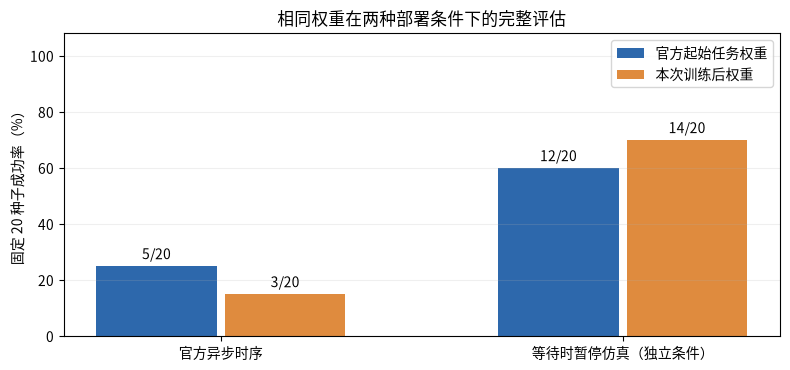

每组各 20 个固定种子；暂停仿真没有提高设备推理速度，不能替代官方异步成绩。


策略,成功回合／完整分母,成功率,权重指纹前缀
官方起始任务权重,12 / 20,60.0%,21640047e97354a6
本次训练后权重,14 / 20,70.0%,7cc8487f7609b05a


策略,适配张量数,允许静默丢弃参数,计时前预热／随机数恢复
官方起始任务权重,20,False,True / True
本次训练后权重,20,False,True / True


种子,基座,训练后,同种子变化
100,成功,成功,相同
101,成功,成功,相同
102,成功,失败,退步
103,失败,失败,相同
104,失败,成功,改善
105,成功,失败,退步
106,失败,失败,相同
107,成功,失败,退步
108,成功,成功,相同
109,失败,成功,改善


总体成功率差： +10.0 个百分点


...

等待列为缓冲区为空时休眠时间之和，未包含循环处理开销；墙钟列包含完整回合耗时。视频按物理仿真步播放，此条件不代表实时推理性能。
本结果只适用于记录的单任务、种子、划分及配方；相同成功率不代表每个回合行为相同。


**官方起始任务权重 · 种子 100 · 成功**

**官方起始任务权重 · 种子 103 · 失败**

**本次训练后权重 · 种子 100 · 成功**

**本次训练后权重 · 种子 102 · 失败**

In [25]:
CLOCK_RECORDED = TOPIC / 'notebooks/results/dexjoco_clock'
from amd_benchmarks.evidence import plot_deployment_conditions
plot_deployment_conditions(TOPIC / 'notebooks/results/dexjoco', CLOCK_RECORDED)
compare_policies(CLOCK_RECORDED)
show_recorded_videos(CLOCK_RECORDED)


## 笔记本内直接播放：训练后评估录像

以下播放器保存真实完整视频数据，下载笔记本后可直接播放；原有逐回合结果、成功与失败标注仍保留在前文。视频用于观察本篇记录的策略行为，训练条件与分母以本篇结果表为准。

本篇评估录像：`trained_seed_100.mp4`

In [26]:
from pathlib import Path
from IPython.display import Video, display
_VIDEO_TOPIC = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "code/amd_benchmarks").is_dir())
display(Video(filename=str(_VIDEO_TOPIC / 'notebooks/results/dexjoco/videos/trained_seed_100.mp4'), embed=True, width=640))


本篇评估录像：`trained_seed_104.mp4`

In [27]:
from pathlib import Path
from IPython.display import Video, display
_VIDEO_TOPIC = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "code/amd_benchmarks").is_dir())
display(Video(filename=str(_VIDEO_TOPIC / 'notebooks/results/dexjoco/videos/trained_seed_104.mp4'), embed=True, width=640))
